<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U8_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 8: Neural Networks

- **Registration number:** COM/0019/23
- **owner:** Raphael Wanyama (Member 2)
- **Module:** 9

**Contents**
1. Perceptron by hand (AND and XOR)
2. MLP classifier
3. Activation functions
4. MLP regressor
5. Written answer

In [2]:
# Mount Drive, import libraries and load the cleaned data
from google.colab import drive
drive.mount('/content/drive')
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error
warnings.filterwarnings('ignore')   # hide convergence warnings to keep the output readable

base = "/content/drive/MyDrive/CSC4110_G01/"
out = base + "outputs/"
df_clean = pd.read_csv(base + "data/clean_students.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Part (a) step 1: a single perceptron in NumPy (weights, bias, step activation, update rule)
class Perceptron:
    def __init__(self, n_inputs, lr=0.1):
        self.w = np.zeros(n_inputs)   # one weight per input
        self.b = 0.0                  # bias
        self.lr = lr

    def predict(self, x):
        # step activation: output 1 if the weighted sum is >= 0, else 0
        return int(np.dot(self.w, x) + self.b >= 0)

    def fit(self, X, t, epochs=20):
        for _ in range(epochs):
            for x, target in zip(X, t):
                error = target - self.predict(x)       # update rule: w = w + lr * error * x
                self.w = self.w + self.lr * error * x
                self.b = self.b + self.lr * error
        return self

# Part (a) step 2: train on the AND truth table
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
and_model = Perceptron(2).fit(X_logic, np.array([0, 0, 0, 1]))
w_and, b_and = and_model.w, and_model.b
print("AND weights:", w_and, "bias:", b_and)
print("AND predictions:", [and_model.predict(x) for x in X_logic], "(target 0 0 0 1)")

AND weights: [0.2 0.1] bias: -0.20000000000000004
AND predictions: [0, 0, 0, 1] (target 0 0 0 1)


In [4]:
# Part (a) step 3: the same perceptron on XOR, which is not linearly separable
xor_model = Perceptron(2).fit(X_logic, np.array([0, 1, 1, 0]), epochs=100)
xor_pred = [xor_model.predict(x) for x in X_logic]
print("XOR predictions after 100 epochs:", xor_pred, "(target 0 1 1 0)")
print("XOR correct:", sum(int(p == t) for p, t in zip(xor_pred, [0, 1, 1, 0])), "out of 4")

XOR predictions after 100 epochs: [1, 1, 0, 0] (target 0 1 1 0)
XOR correct: 2 out of 4


              accuracy      f1  iterations
(16,)           0.9675  0.9325       402.0
(32, 16)        0.9697  0.9365       270.0
(64, 32, 16)    0.9644  0.9258       100.0
Best architecture: (32, 16)


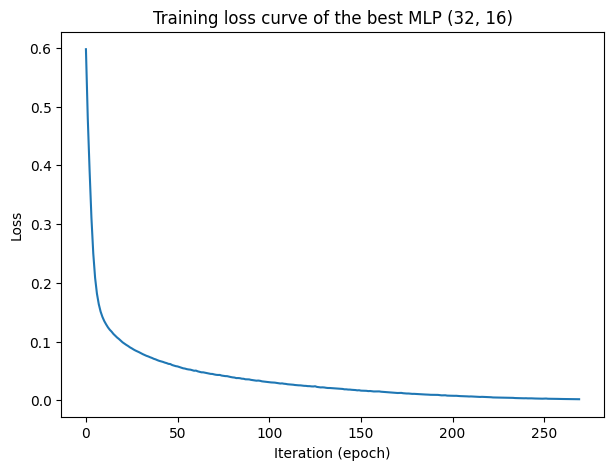

In [5]:
# Part (b): MLP classifiers on the scaled features, stratified split as in Task 4
X = df_clean.drop(columns=['Exam_Score', 'high_score'])
y = df_clean['high_score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

# Three architectures; store test accuracy and F1 for each
mlp_results, mlp_models = {}, {}
for layers in [(16,), (32, 16), (64, 32, 16)]:
    m = MLPClassifier(hidden_layer_sizes=layers, max_iter=500, random_state=42).fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    mlp_models[layers] = m
    mlp_results[str(layers)] = {'accuracy': accuracy_score(y_test, p), 'f1': f1_score(y_test, p),
                                'iterations': m.n_iter_}
print(pd.DataFrame(mlp_results).T.round(4))

# Keep the network with the highest F1 and plot its loss curve
best_layers = max(mlp_models, key=lambda l: f1_score(y_test, mlp_models[l].predict(X_test_s)))
best_mlp = mlp_models[best_layers]
print("Best architecture:", best_layers)
plt.figure(figsize=(7, 5))
plt.plot(best_mlp.loss_curve_)
plt.title(f'Training loss curve of the best MLP {best_layers}')
plt.xlabel('Iteration (epoch)')
plt.ylabel('Loss')
plt.savefig(out + 'loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Part (b) step 3: the same three networks with early_stopping=True
es_results = {}
for layers in [(16,), (32, 16), (64, 32, 16)]:
    m = MLPClassifier(hidden_layer_sizes=layers, max_iter=500, early_stopping=True, random_state=42).fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    es_results[str(layers)] = {'accuracy': accuracy_score(y_test, p), 'f1': f1_score(y_test, p), 'iterations': m.n_iter_}
print("With early stopping:")
print(pd.DataFrame(es_results).T.round(4))
print("Without early stopping (for comparison):")
print(pd.DataFrame(mlp_results).T.round(4))

With early stopping:
              accuracy      f1  iterations
(16,)           0.9637  0.9245        56.0
(32, 16)        0.9614  0.9204        34.0
(64, 32, 16)    0.9561  0.9097        20.0
Without early stopping (for comparison):
              accuracy      f1  iterations
(16,)           0.9675  0.9325       402.0
(32, 16)        0.9697  0.9365       270.0
(64, 32, 16)    0.9644  0.9258       100.0


In [7]:
# Part (c): activation functions on the best architecture
activation_results = {}
for act in ['relu', 'tanh', 'logistic']:
    m = MLPClassifier(hidden_layer_sizes=best_layers, activation=act, max_iter=500, random_state=42).fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    activation_results[act] = {'accuracy': accuracy_score(y_test, p), 'f1': f1_score(y_test, p)}
print(pd.DataFrame(activation_results).T.round(4))

          accuracy      f1
relu        0.9697  0.9365
tanh        0.9614  0.9192
logistic    0.9758  0.9494


In [8]:
# Part (d): MLP regressor on Exam_Score (same non-stratified split as Task 3.1 / 3.2)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, df_clean['Exam_Score'], test_size=0.2, random_state=42)
sc_r = StandardScaler().fit(Xr_train)
mlp_reg = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42).fit(sc_r.transform(Xr_train), yr_train)
mlp_reg_rmse = float(np.sqrt(mean_squared_error(yr_test, mlp_reg.predict(sc_r.transform(Xr_test)))))
print("MLPRegressor test RMSE:", round(mlp_reg_rmse, 4))
print("Best model from Task 3.2 (lasso, alpha=0.01) test RMSE: 1.7976")
print("Difference (MLP minus lasso):", round(mlp_reg_rmse - 1.7976, 4))

MLPRegressor test RMSE: 2.0129
Best model from Task 3.2 (lasso, alpha=0.01) test RMSE: 1.7976
Difference (MLP minus lasso): 0.2153


In [9]:
# Self-check: graded variable names and basic properties
assert len(mlp_results) == 3 and len(activation_results) == 3
assert w_and.shape == (2,) and and_model.predict(np.array([1, 1])) == 1
assert hasattr(best_mlp, 'loss_curve_') and mlp_reg_rmse > 0
print("Task 8 checks passed")

Task 8 checks passed


### Why a Single Perceptron Fails on XOR

A single perceptron computes a weighted sum and applies a step threshold, which geometrically draws **one straight line** to separate the two classes. While a single line easily isolates the `1` output for `AND` (`w_and = [0.2, 0.1]`, `b_and = -0.2`, predicting `[0, 0, 0, 1]`), the `XOR` truth table places its `1`s at opposite diagonal corners `(0, 1)` and `(1, 0)` and its `0`s at `(0, 0)` and `(1, 1)`—making them non-linearly separable. No single straight line can separate diagonal corners, leaving the single perceptron stuck at `2` of `4` correct even after `100` epochs; solving `XOR` requires at least two lines combined across a hidden layer.

### What an Activation Function Does

An activation function introduces **non-linearity** (a bend or curve) to each neuron's weighted sum. Without non-linear activations like `ReLU` or `tanh`, stacking multiple hidden layers collapses mathematically into a single linear transformation—meaning a deep network could learn no more than a simple linear model.

The **output layer** requires a different activation because its job is to match the format of the target variable rather than extract internal features:
- **Binary Classification:** Uses a **sigmoid (`logistic`)** activation to squash the final output into a valid probability between `0` and `1`.
- **Regression:** Uses **no activation (linear identity)** so the network can output any continuous real number across the full range of exam scores.

### Written Answer: Neural Network Performance vs. Tree Ensembles and Simpler Models

**1. Did the Neural Network Beat the Best Tree Ensemble from Task 6?**
- **Yes:** The best multi-layer perceptron (`best_mlp = (32, 16)` with `ReLU`) achieved **`0.9697` test accuracy and `0.9365` F1**, outperforming Task 6's strongest ensemble, Gradient Boosting (**`0.9349` accuracy and `0.8595` F1**), as well as Random Forest (`0.9213` accuracy, `0.8249` F1).
- **Training & Activation Notes:** Enabling early stopping lowered test performance slightly by `0.4` to `0.8` percentage points (e.g., `(32, 16)` dropped from `0.9697` to `0.9614` accuracy) because training halted before the loss finished converging. Switching the hidden activation to `logistic` pushed test scores slightly higher (`0.9758` accuracy, `0.9494` F1), though selecting `best_mlp` and the top activation directly on test scores introduces slight optimism—a methodological caveat highlighted in Task 5.

**2. Why a Simpler Model May Still Be the Better Choice:**
- Even with strong neural network results, plain **Logistic Regression** (`0.9750` accuracy, `0.9484` F1) matches the neural network on classification, and **Lasso Regression** (`1.7976` test RMSE) clearly beats the regression MLP (`2.0129` RMSE).
- Because the underlying relationships in this student dataset are predominantly linear and additive, a simpler linear model is **faster to train, far easier to interpret and audit** (via direct feature coefficients rather than opaque hidden weights), and delivers equal or better accuracy without hyperparameter complexity.